# Registration Methods
 4 methods:
 - register_parameter( name , param)  
 - register_buffer( name , tensor , persistent=True)
 - register_module(name,module)

 ## register_parameter

In [17]:
import torch
import torch.nn as nn

model = nn.Module()

model.register_parameter("temperature", nn.Parameter(torch.ones(1)))
print(model.temperature)
model.state_dict()


Parameter containing:
tensor([1.], requires_grad=True)


OrderedDict([('temperature', tensor([1.]))])

## register_buffer


In [18]:
model=nn.Module()

model.register_buffer("mask",torch.tensor(3.0))
print(model.mask)
print(model.state_dict())

# 1. Extract the state dict (includes weights + your registered "mask" buffer)
snapshot = model.state_dict()

# 2. Save it to a file on your hard drive
torch.save(snapshot, 'my_model_weights.pth')

tensor(3.)
OrderedDict({'mask': tensor(3.)})


### applying the none trick


In [19]:
import torch
import torch.nn as nn

model = nn.Module()
model.register_buffer("mask", torch.ones(3))
model.register_parameter("weight", nn.Parameter(torch.randn(3)))

print("Before:", list(model.state_dict().keys()))
# Output: ['weight', 'mask']

# 💡 Apply the None trick
model.mask = None
model.weight = None

print("After:", list(model.state_dict().keys()))
# Output: [] (They are completely unregistered!)


Before: ['weight', 'mask']
After: []


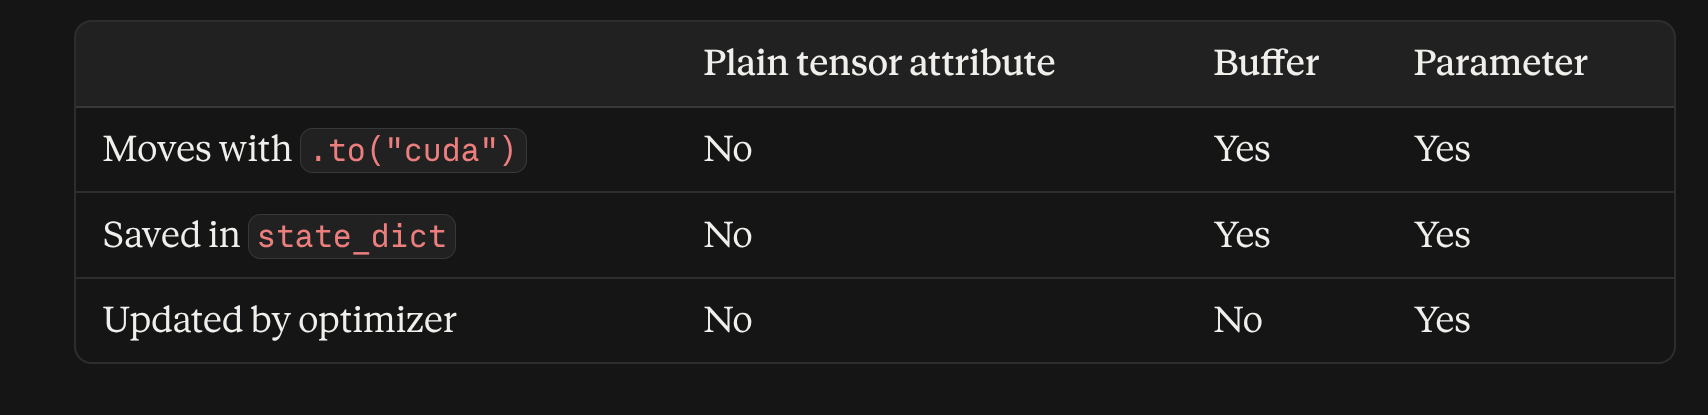

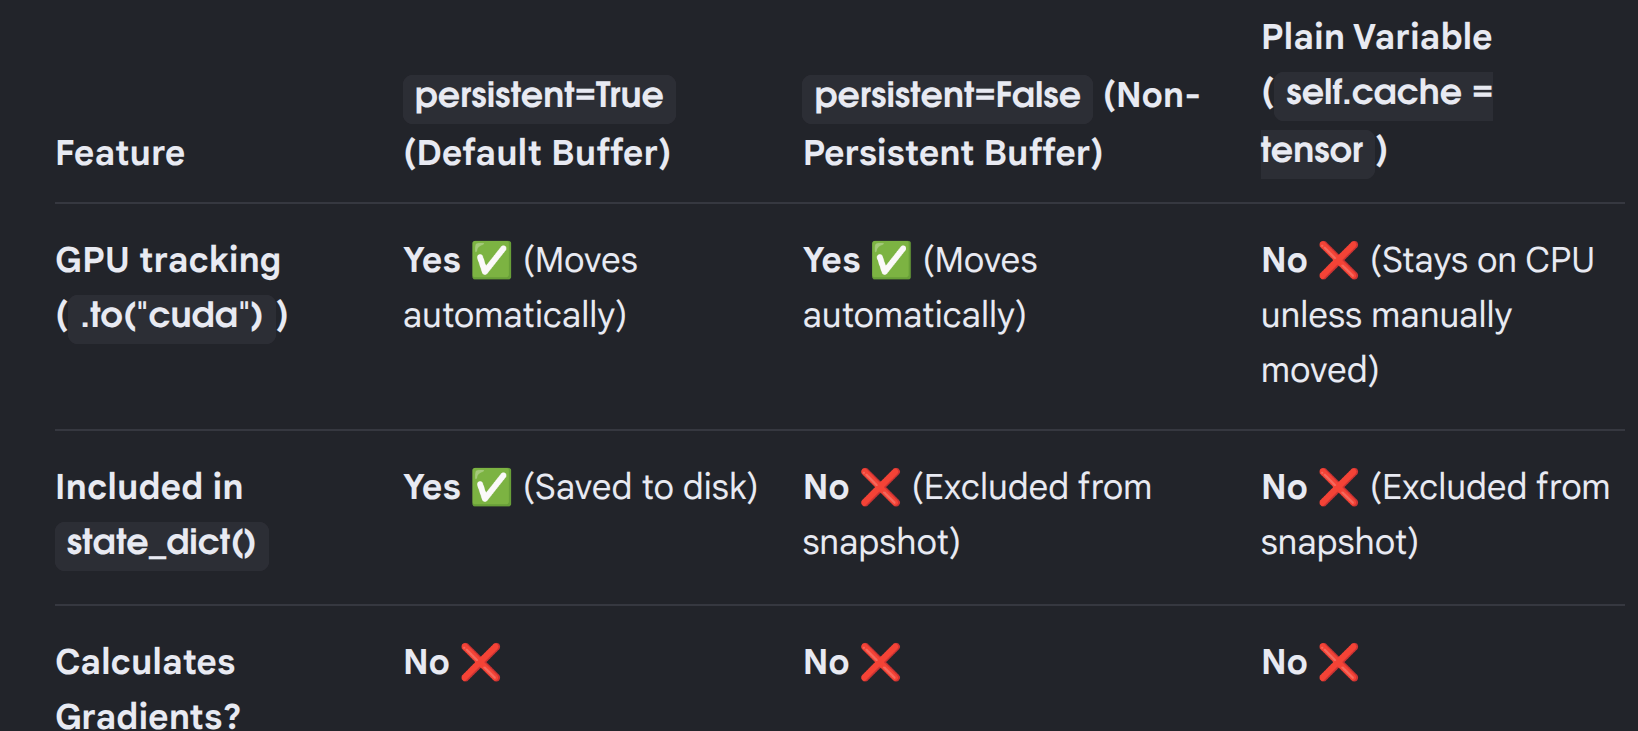

In [20]:
# use of persistent

model=nn.Module()

model.register_buffer("cache", torch.zeros(3), persistent=False) #can tracked by GPU but not saved locally(by state_dict())

model.register_buffer("true_cache",torch.zeros(2),persistent=True) # can tracked by GPU and also be saved locally(by state_dict())
print(model.state_dict())

OrderedDict({'true_cache': tensor([0., 0.])})


## add_module(name,module)

In [21]:
for i in range(3):
    model.add_module(f"extra{i}", nn.Linear(2, 2))

print([n for n, _ in model.named_children()])
# [..., 'extra0', 'extra1', 'extra2']
print(model.state_dict())

['extra0', 'extra1', 'extra2']
OrderedDict({'true_cache': tensor([0., 0.]), 'extra0.weight': tensor([[-0.1807, -0.5410],
        [ 0.0898, -0.3896]]), 'extra0.bias': tensor([-0.6538,  0.6829]), 'extra1.weight': tensor([[-0.2683, -0.1411],
        [-0.3655,  0.5069]]), 'extra1.bias': tensor([-0.6514, -0.5481]), 'extra2.weight': tensor([[-0.0245,  0.2078],
        [-0.6619, -0.2760]]), 'extra2.bias': tensor([ 0.3240, -0.1033])})


- This is useful when the number or names of layers come from a variable, like a loop or a config file. Note that self.fc = nn.Linear(...) does the same thing under the hood, but the name fc is fixed in your code.

In [22]:
# passing None
model.add_module("fake",None)
print("Registered children:", [n for n, _ in model.named_children()])


Registered children: ['extra0', 'extra1', 'extra2']


- When you call model.add_module("fake", None), PyTorch does successfully register "fake" inside the internal module tracker. However, the method named_children() has a hidden filter built into its source code: it completely skips over any module that equals None.


- for viewing None value's name use _module that does not hide anything

In [23]:
# 💡 FIX: Check the raw internal notebook dictionary directly
print("All registered modules:", list(model._modules.keys()))


All registered modules: ['extra0', 'extra1', 'extra2', 'fake']


In [24]:
model.state_dict()

OrderedDict([('true_cache', tensor([0., 0.])),
             ('extra0.weight',
              tensor([[-0.1807, -0.5410],
                      [ 0.0898, -0.3896]])),
             ('extra0.bias', tensor([-0.6538,  0.6829])),
             ('extra1.weight',
              tensor([[-0.2683, -0.1411],
                      [-0.3655,  0.5069]])),
             ('extra1.bias', tensor([-0.6514, -0.5481])),
             ('extra2.weight',
              tensor([[-0.0245,  0.2078],
                      [-0.6619, -0.2760]])),
             ('extra2.bias', tensor([ 0.3240, -0.1033]))])

## set_submodule(target,module)

In [25]:
class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(8, 8)

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = Block()

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.fc2 = nn.Linear(8, 3)

model = Net()

In [26]:
model.state_dict() # before changing shape of fc2 is (8,3)

OrderedDict([('encoder.block1.fc.weight',
              tensor([[ 0.1540,  0.1898, -0.0466,  0.2809, -0.1032, -0.2045, -0.2874, -0.0073],
                      [ 0.3117,  0.0924,  0.0511,  0.1985, -0.0233, -0.1003, -0.0794, -0.1836],
                      [-0.2587,  0.2683, -0.1227,  0.3526,  0.1569,  0.0618, -0.3170, -0.0711],
                      [ 0.0549, -0.0071,  0.0330,  0.2459,  0.0213,  0.1947, -0.2480,  0.1035],
                      [ 0.2357, -0.2448, -0.0025,  0.3499,  0.2766,  0.3115, -0.0320, -0.1492],
                      [ 0.2531,  0.2876, -0.3510,  0.3450, -0.0400,  0.0784,  0.0736,  0.0651],
                      [ 0.2490, -0.0919,  0.3382,  0.0296, -0.3317,  0.0053,  0.1577, -0.0735],
                      [ 0.1046,  0.0252, -0.2401, -0.3020, -0.0659,  0.2814, -0.0203, -0.2039]])),
             ('encoder.block1.fc.bias',
              tensor([ 0.2833,  0.0563,  0.1395,  0.1262, -0.0576,  0.1245,  0.2597,  0.1147])),
             ('fc2.weight',
              tensor([

In [27]:
model.set_submodule("fc2",nn.Linear(3,8)) # after this it's shape would become (3,8)

## what set_submodule() does->>

- PyTorch follows the path "fc2" to find the current layer.
- It throws that old layer away (old weights included).
- It puts your new layer there.

In [28]:
model.state_dict()

OrderedDict([('encoder.block1.fc.weight',
              tensor([[ 0.1540,  0.1898, -0.0466,  0.2809, -0.1032, -0.2045, -0.2874, -0.0073],
                      [ 0.3117,  0.0924,  0.0511,  0.1985, -0.0233, -0.1003, -0.0794, -0.1836],
                      [-0.2587,  0.2683, -0.1227,  0.3526,  0.1569,  0.0618, -0.3170, -0.0711],
                      [ 0.0549, -0.0071,  0.0330,  0.2459,  0.0213,  0.1947, -0.2480,  0.1035],
                      [ 0.2357, -0.2448, -0.0025,  0.3499,  0.2766,  0.3115, -0.0320, -0.1492],
                      [ 0.2531,  0.2876, -0.3510,  0.3450, -0.0400,  0.0784,  0.0736,  0.0651],
                      [ 0.2490, -0.0919,  0.3382,  0.0296, -0.3317,  0.0053,  0.1577, -0.0735],
                      [ 0.1046,  0.0252, -0.2401, -0.3020, -0.0659,  0.2814, -0.0203, -0.2039]])),
             ('encoder.block1.fc.bias',
              tensor([ 0.2833,  0.0563,  0.1395,  0.1262, -0.0576,  0.1245,  0.2597,  0.1147])),
             ('fc2.weight',
              tensor([

In [29]:
## for deeper layer use dots

model.set_submodule("encoder.block1.fc",nn.Linear(20,3))

In [30]:
model.state_dict()

OrderedDict([('encoder.block1.fc.weight',
              tensor([[-0.0753, -0.1775, -0.0746,  0.0813, -0.2060, -0.1594,  0.0583, -0.0705,
                        0.1611,  0.0453,  0.1918,  0.2165, -0.2184,  0.0396,  0.0418,  0.1071,
                       -0.1449, -0.1022, -0.0386, -0.1035],
                      [ 0.1170, -0.0748, -0.0176,  0.0118, -0.1714,  0.0995, -0.1765,  0.0697,
                       -0.1723,  0.0343,  0.1035, -0.1006, -0.1102, -0.1187,  0.1737,  0.1269,
                       -0.0248, -0.1732,  0.0079, -0.1184],
                      [-0.0204,  0.0892, -0.0673,  0.1332,  0.1432,  0.1402,  0.0217, -0.0089,
                       -0.0977,  0.2044, -0.0173, -0.1811, -0.0414, -0.1200,  0.1128, -0.1020,
                        0.0353,  0.0179,  0.1555,  0.1431]])),
             ('encoder.block1.fc.bias', tensor([-0.0699,  0.0633,  0.1849])),
             ('fc2.weight',
              tensor([[ 0.4356,  0.3845, -0.5589],
                      [-0.1954, -0.5450,  0.2378

### Twin of set_submodule() : get_submodule()

In [31]:
layer=model.get_submodule("encoder.block1.fc")
print(layer)

Linear(in_features=20, out_features=3, bias=True)


In [34]:
# 1. freeze the pretrained body
for p in model.parameters():
    p.requires_grad = False

# 2. replace the head (new layers are trainable by default)
model.set_submodule("fc", nn.Linear(512, 10))

# 3. create the optimizer AFTER the swap
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

In [35]:
model.state_dict()

OrderedDict([('encoder.block1.fc.weight',
              tensor([[-0.0753, -0.1775, -0.0746,  0.0813, -0.2060, -0.1594,  0.0583, -0.0705,
                        0.1611,  0.0453,  0.1918,  0.2165, -0.2184,  0.0396,  0.0418,  0.1071,
                       -0.1449, -0.1022, -0.0386, -0.1035],
                      [ 0.1170, -0.0748, -0.0176,  0.0118, -0.1714,  0.0995, -0.1765,  0.0697,
                       -0.1723,  0.0343,  0.1035, -0.1006, -0.1102, -0.1187,  0.1737,  0.1269,
                       -0.0248, -0.1732,  0.0079, -0.1184],
                      [-0.0204,  0.0892, -0.0673,  0.1332,  0.1432,  0.1402,  0.0217, -0.0089,
                       -0.0977,  0.2044, -0.0173, -0.1811, -0.0414, -0.1200,  0.1128, -0.1020,
                        0.0353,  0.0179,  0.1555,  0.1431]])),
             ('encoder.block1.fc.bias', tensor([-0.0699,  0.0633,  0.1849])),
             ('fc2.weight',
              tensor([[ 0.4356,  0.3845, -0.5589],
                      [-0.1954, -0.5450,  0.2378